# v9f: PATCHING + STEERING: does the self carry WHICH LANGUAGE is written? (GPU 1, no training)
- Models: mixed 45 (knows all 3 languages best), distant 30, related 15. Decoder layers only (the encoder only sees English).
- Groups: 30% of each decoder layer: self / look-alike task / random task (3 draws).
- PATCH: model asked for language A; the group's neurons are replaced by their activity when the SAME sentence is translated into B.
- STEER: add alpha x (average activity in B - in A) to the group's neurons (alpha 1, 2, 4).
- Measured: does the B translation become more likely (shift to B)? does A get worse? and in generation: % of output in B's script.
- Prediction if the self is shared machinery: patching the self barely moves the output to B; task neurons move it more.
Results: `analysis/v9/patch/`. Progress: `tail -f logs/patch_v9.log`.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "1"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)

def run(langset, *cmd):
    """runs one call, shows the output here AND appends it to logs/patch_v9.log (watch with: tail -f logs/patch_v9.log)"""
    env = {**os.environ, "CML_LANGSET": langset}; os.makedirs("logs", exist_ok=True)
    p = subprocess.Popen([sys.executable, "-u", "patch_v9.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    with open("logs/patch_v9.log", "a") as log:
        for line in p.stdout:
            print(line, end=""); log.write(line); log.flush()
    p.wait(); print("exit code", p.returncode)

DIST, REL, MIX = "v4b_continual_s0", "v8_indic_continual_s0", "v6b_mixed_s0"
STARTS = [("distant", "mixed45", MIX, 45), ("distant", "distant30", DIST, 30), ("indic", "related15", REL, 15)]
for _, _, r, ph in STARTS:
    get(r, [ph])
print("start models:", [(n, r, ph) for _, n, r, ph in STARTS])

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


p045_mix.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

start models: [('mixed45', 'v6b_mixed_s0', 45), ('distant30', 'v4b_continual_s0', 30), ('related15', 'v8_indic_continual_s0', 15)]


In [2]:
need = [f"data/en-{l}/train.jsonl" for l in ["hi", "zh", "gu"]] + [f"data/flores/devtest.{l}.jsonl" for l in ["en", "hi", "zh", "gu"]]
need += [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar", "gu", "pa"]] + [f"data/en-{l}/val.jsonl" for l in ["hi", "zh", "ar", "gu", "pa"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}  -> run your download snippet first, then re-run this cell")

all there


start model: mixed45 = v6b_mixed_s0 phase 45 | languages ['hi', 'zh', 'ar']


  dec0.mlp: self 1603 of 2560 working neurons; groups of 768
  dec1.mlp: self 1435 of 2560 working neurons; groups of 768
  dec2.mlp: self 1484 of 2560 working neurons; groups of 768
  dec3.mlp: self 2011 of 2560 working neurons; groups of 768
  self found in 9s


baseline loss of the B reference when asked for A (rows A, columns B):
       hi     zh     ar
hi  4.339  6.703  5.223
zh  4.521  6.196  5.238
ar  4.580  6.771  4.975


  asked hi: script share hi 88%, zh 3%, ar 10% | chrF 0.9


  asked zh: script share hi 43%, zh 30%, ar 28% | chrF 0.3


  asked ar: script share hi 21%, zh 3%, ar 76% | chrF 0.2
    dec3.mlp: group too small, skipped


... (183 outputs left out)

  draw 2 | random    | asked pa, pushed to gu | shift to B: patch_all -0.147, steer a2 -0.011 | generated gu script: patch 1% steer 1% (normally 2%)
done


exit code 0


=== v9 patching + steering: does the self carry WHICH LANGUAGE is written? ===
shift_to_B > 0: the B translation became more likely while the model was asked for A. damage_A > 0: the A translation got worse.
average over language pairs and draws:

                       shift_to_B                damage_A              
group                   lookalike random   self lookalike random   self
start     intervention                                                 
distant30 patch_all        -0.113 -0.159 -0.337     0.150  0.195  0.299
          patch_dec0       -0.037 -0.047 -0.155     0.049  0.061  0.169
          patch_dec1       -0.018 -0.026 -0.084     0.026  0.038  0.093
          patch_dec2       -0.035 -0.028 -0.036     0.051  0.038 -0.012
          patch_dec3        0.000  0.000  0.000     0.000  0.000  0.000
          steer_a1          0.019  0.017 -0.039     0.029  0.028 -0.027
          steer_a2          0.028  0.024 -0.095     0.069  0.066 -0.040
          steer_a4          0.01

figures + report in /workspace/shreshth/analysis/v9/patch


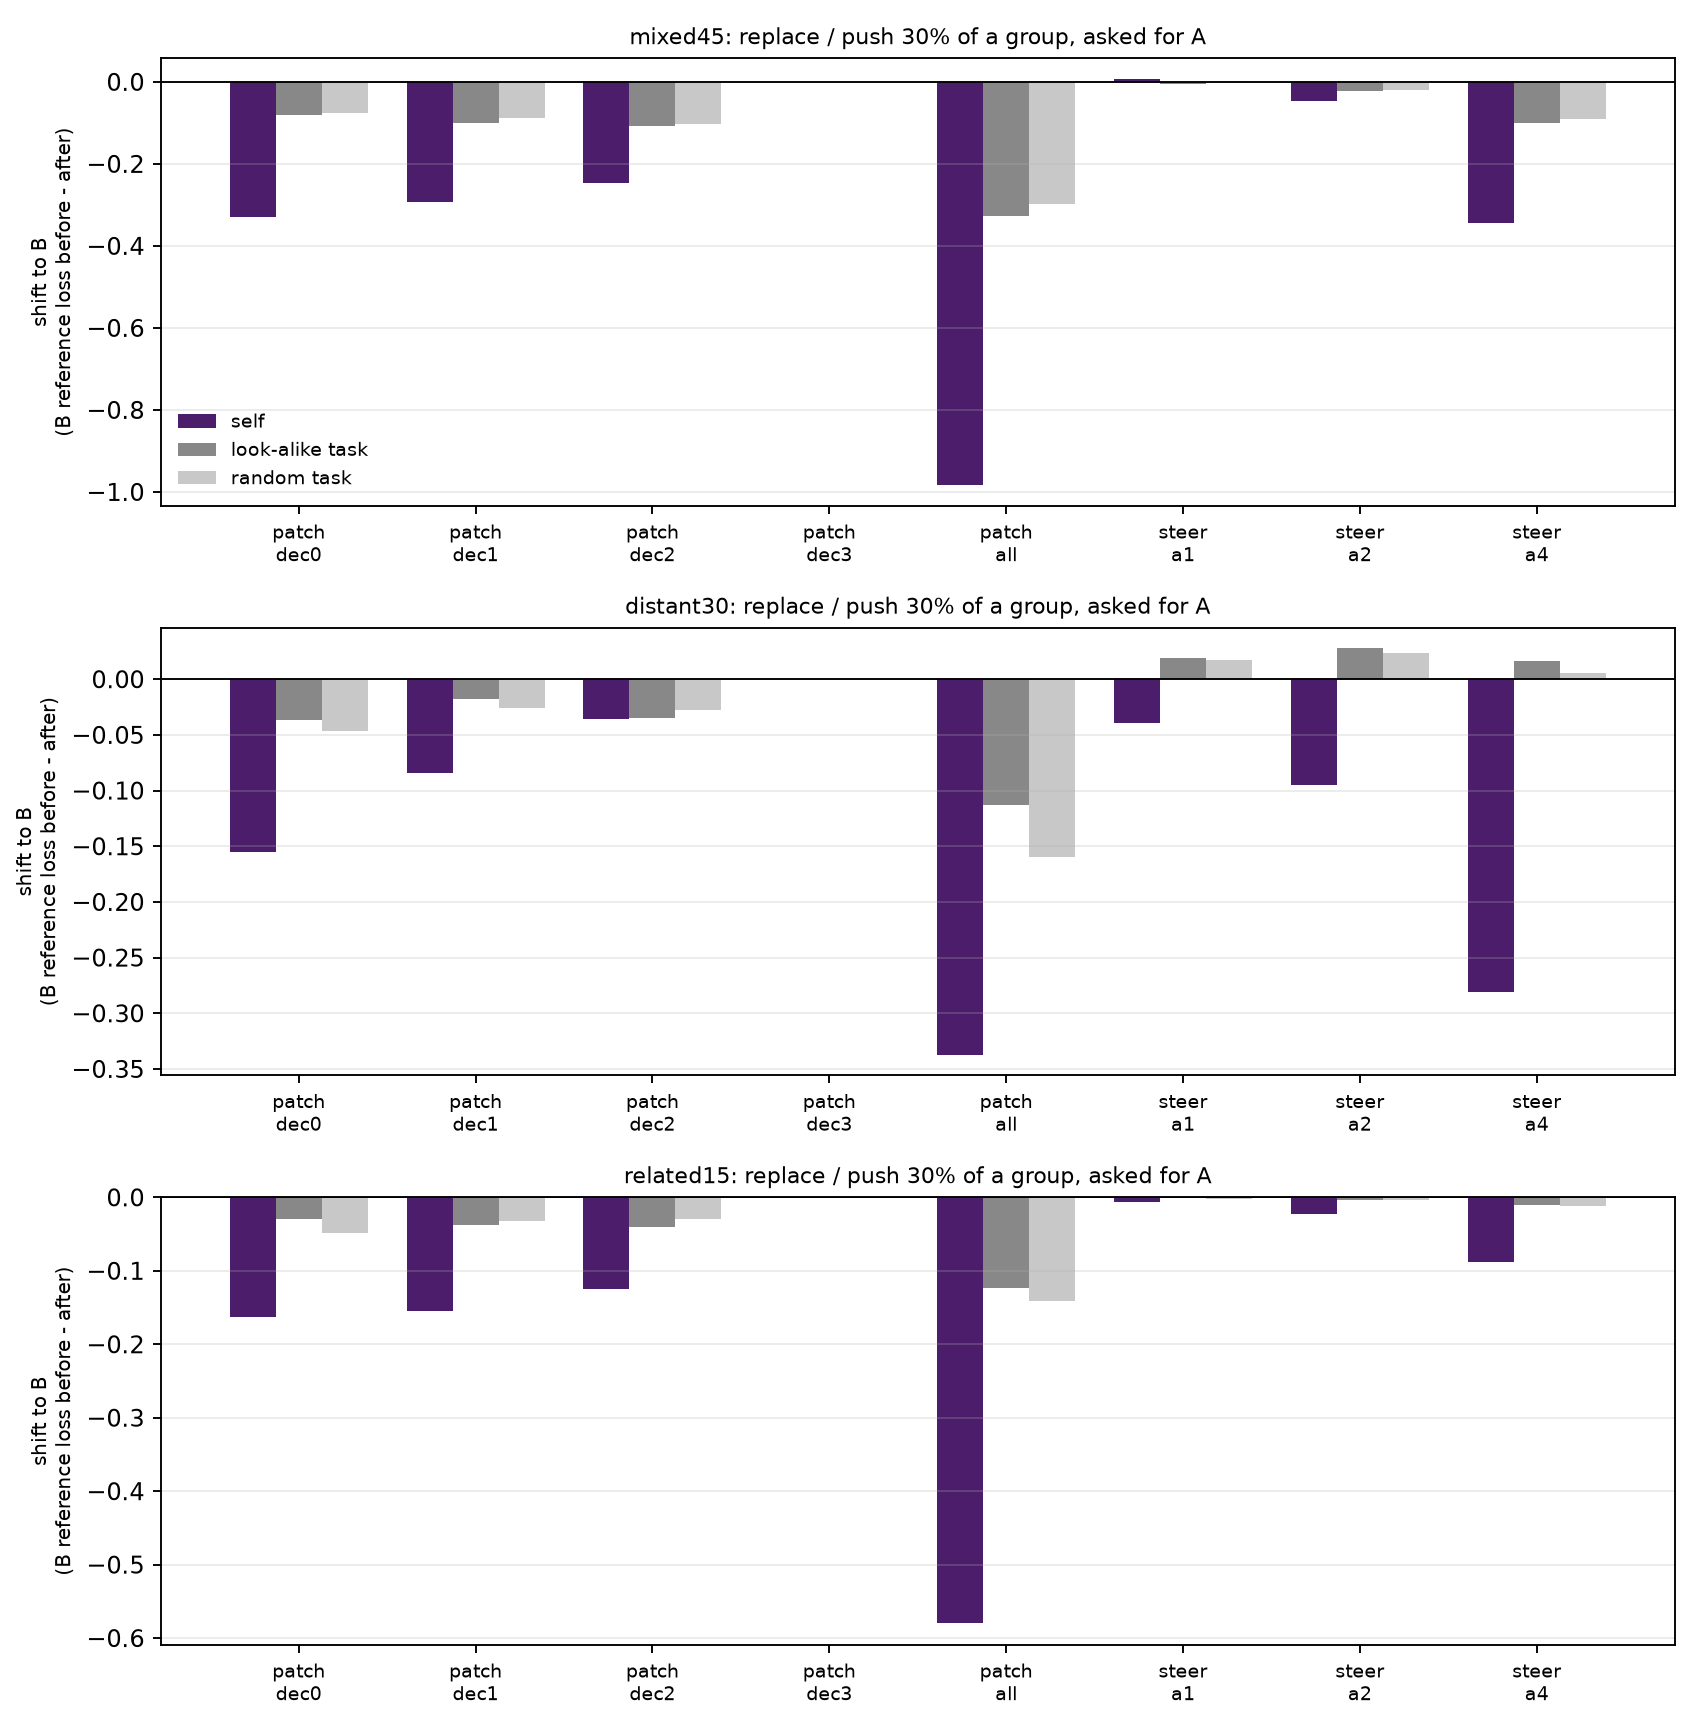

In [3]:
for langset, name, r, ph in STARTS:
    run(langset, "--start", f"{name}={r}:{ph}")
subprocess.run([sys.executable, "patch_v9.py", "--summarize"])
display(Image("analysis/v9/patch/fig1_shift_to_B.png"))